# Taller Aplicado 2 — Plantilla base (trabajo autónomo)
**Benchmarking de modelos estadísticos clásicos y redes NAR/NARX sobre una serie real**

Esta plantilla trae resuelto el *andamiaje* del experimento: carga, validación del dataset, preprocesamiento sin fuga, diagnóstico, validación cruzada de origen móvil, métricas, residuos, prueba de Diebold-Mariano y exportación de resultados. **El diseño, la identificación y la optimización de los modelos son responsabilidad del equipo**: están marcados con `TODO-EQUIPO`.

El cuaderno corre de punta a punta desde el inicio con el modelo de referencia (ingenuo estacional). Los modelos que aún no implementen se omiten con un aviso.

## 0. Configuración del experimento

In [1]:
# =====================================================================
#                       CONFIGURACIÓN (editar)
# =====================================================================
DATASET     = "beijing"      # 'appliances' | 'beijing' | 'jena' | 'propio' | 'sintetico' (prueba rápida)
RUTA_PROPIA = "/content/mis_datos.csv"   # Solo si DATASET='propio'. CSV con una columna de fecha.
COL_FECHA   = "fecha"                    # Nombre de la columna de fecha en el CSV propio.

OBJETIVO    = None    # None = valor por defecto del dataset (ver diccionario FUENTES).
EXOGENAS    = None    # Lista de columnas exógenas; None = valores por defecto; [] = sin exógenas.
FRECUENCIA  = None    # Remuestreo pandas ('h', 'D', ...). None = por defecto del dataset.
S           = None    # Periodo estacional en pasos de FRECUENCIA (24 para horario-diario, 7 para diario-semanal).

PROP_PRUEBA = 0.20    # Fracción final reservada como prueba EXTERNA (no se toca hasta el final).
N_PLIEGUES  = 5       # Orígenes de la validación cruzada de origen móvil dentro de la parte de desarrollo.
HORIZONTE   = 24      # Pasos a pronosticar desde cada origen.
VENTANA     = "expandible"   # 'expandible' o 'deslizante'
LONG_VENTANA_DESLIZANTE = 2000
SEMILLA     = 2026

## 1. Librerías

In [2]:
import os, io, zipfile, urllib.request, random, time, itertools, warnings, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")
random.seed(SEMILLA); np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})

## 2. Carga de datos
Fuentes verificadas (UCI Machine Learning Repository y TensorFlow). Las descargas se guardan en `./datos/`.

In [3]:
FUENTES = {
    "appliances": dict(url="https://archive.ics.uci.edu/static/public/374/appliances+energy+prediction.zip",
                       objetivo="Appliances", exogenas=["T_out", "RH_out", "Windspeed"], frecuencia="h", s=24),
    "beijing":    dict(url="https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip",
                       objetivo="PM2.5", exogenas=["TEMP", "DEWP", "PRES", "WSPM"], frecuencia="D", s=7,
                       estacion="Aotizhongxin"),
    "jena":       dict(url="https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip",
                       objetivo="T (degC)", exogenas=["p (mbar)", "rh (%)"], frecuencia="h", s=24),
    "propio":     dict(objetivo=None, exogenas=[], frecuencia=None, s=None),
    "sintetico":  dict(objetivo="y", exogenas=["x"], frecuencia="D", s=7),
}

def descargar(url):
    os.makedirs("datos", exist_ok=True)
    destino = os.path.join("datos", url.split("/")[-1])
    if not os.path.exists(destino):
        print("Descargando", url)
        urllib.request.urlretrieve(url, destino)
    return destino

def leer_csv_de_zip(ruta_zip, contiene=".csv"):
    # Recorre zips anidados (Beijing trae un zip dentro de otro) hasta hallar el CSV pedido.
    with zipfile.ZipFile(ruta_zip) as z:
        for nombre in z.namelist():
            if nombre.endswith(".csv") and contiene in nombre:
                return pd.read_csv(z.open(nombre))
        for nombre in z.namelist():
            if nombre.endswith(".zip"):
                return leer_csv_de_zip(io.BytesIO(z.read(nombre)), contiene)
    raise FileNotFoundError(f"No se encontró un CSV que contenga '{contiene}'")

def cargar_datos(nombre):
    f = FUENTES[nombre]
    if nombre == "appliances":
        df = leer_csv_de_zip(descargar(f["url"]), "energydata")
        df.index = pd.to_datetime(df.pop("date"))
    elif nombre == "beijing":
        df = leer_csv_de_zip(descargar(f["url"]), f["estacion"])
        df.index = pd.to_datetime(df[["year", "month", "day", "hour"]])
        df = df.drop(columns=["No", "year", "month", "day", "hour", "wd", "station"])
    elif nombre == "jena":
        df = leer_csv_de_zip(descargar(f["url"]), "jena_climate")
        df.index = pd.to_datetime(df.pop("Date Time"), format="%d.%m.%Y %H:%M:%S")
        dup = df.index.duplicated()                       # el archivo trae marcas de tiempo repetidas
        print(f"Jena: {dup.sum()} registros duplicados eliminados (documentar en el informe)")
        df = df[~dup]
    elif nombre == "propio":
        df = pd.read_csv(RUTA_PROPIA)
        df.index = pd.to_datetime(df.pop(COL_FECHA))
    else:  # serie sintética con la misma lógica del Taller 1, para probar la plantilla sin internet
        t = np.arange(1500); rng = np.random.default_rng(SEMILLA)
        x = 18 + 6*np.sin(2*np.pi*(t-80)/365.25) + rng.normal(0, 1.5, t.size)
        y = 200 + .03*t + 10*np.sin(2*np.pi*t/7) + .35*(x-18)**2 + rng.normal(0, 3, t.size)
        df = pd.DataFrame({"y": y, "x": x}, index=pd.date_range("2020-01-01", periods=t.size, freq="D"))
    return df.sort_index()

cfg = FUENTES[DATASET]
OBJ  = OBJETIVO  or cfg["objetivo"]
EXO  = cfg["exogenas"] if EXOGENAS is None else EXOGENAS
FREC = FRECUENCIA or cfg["frecuencia"]
PER  = S or cfg["s"]
crudo = cargar_datos(DATASET)
print(crudo.shape); display(crudo.head())

(35064, 11)


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
2013-03-01 00:00:00,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,4.4
2013-03-01 01:00:00,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,4.7
2013-03-01 02:00:00,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,5.6
2013-03-01 03:00:00,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,3.1
2013-03-01 04:00:00,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,2.0


## 3. Validación previa del dataset
Criterios mínimos (obligatorios para un **dataset propio** y recomendables para todos). El equipo debe reportar esta tabla en la sección de Metodología del informe.

In [4]:
def validar_dataset(df, obj, exo, frec, per):
    serie = df[obj]
    paso = pd.Series(df.index).diff().dropna()
    criterios = {
        "C1 Índice temporal monótono y sin duplicados": df.index.is_monotonic_increasing and not df.index.duplicated().any(),
        "C2 Muestreo regular (paso modal >= 90% de los casos)": (paso == paso.mode()[0]).mean() >= 0.90,
        "C3 Faltantes en objetivo <= 10%": serie.isna().mean() <= 0.10,
        "C4 Longitud >= 10 periodos estacionales tras remuestreo": len(serie.resample(frec).mean().dropna()) >= 10*per if frec else True,
        "C5 Exógenas existen y son numéricas": all(c in df and pd.api.types.is_numeric_dtype(df[c]) for c in exo),
        "C6 Objetivo no constante": serie.std() > 0,
    }
    tabla = pd.DataFrame({"Cumple": criterios}); display(tabla)
    print(f"Paso modal original: {paso.mode()[0]} | faltantes objetivo: {100*serie.isna().mean():.2f}%")
    # C7 (manual): documentar origen, licencia, unidades y significado de cada variable.
    # C8 (manual): justificar que las exógenas estarían disponibles al momento de pronosticar.
    return tabla["Cumple"].all()

assert validar_dataset(crudo, OBJ, EXO, FREC, PER), "El dataset no cumple los criterios mínimos"

,Cumple
C1 Índice temporal monótono y sin duplicados,True
C2 Muestreo regular (paso modal >= 90% de los casos),True
C3 Faltantes en objetivo <= 10%,True
C4 Longitud >= 10 periodos estacionales tras remuestreo,True
C5 Exógenas existen y son numéricas,True
C6 Objetivo no constante,True


Paso modal original: 0 days 01:00:00 | faltantes objetivo: 2.64%


## 4. Preprocesamiento sin fuga de información
Regla de oro: **todo estadístico que transforme los datos (medias, desviaciones, tendencias, imputaciones con modelos) se estima solo con la parte de entrenamiento de cada pliegue.** Aquí solo se hacen transformaciones que no usan el futuro: remuestreo por agregación e imputación por interpolación temporal local.

Faltantes imputados por columna:
 PM2.5    15
TEMP      0
DEWP      0
PRES      0
WSPM      0
dtype: int64
Total 1461 | desarrollo 1168 (2013-03-01 00:00:00 a 2016-05-11 00:00:00) | prueba externa 293 (2016-05-12 00:00:00 a 2017-02-28 00:00:00)


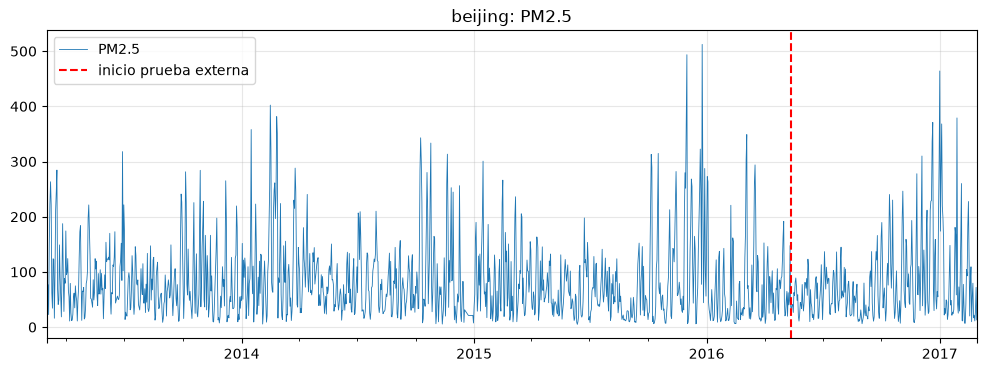

In [5]:
datos = crudo[[OBJ] + EXO].astype(float)
if FREC:
    datos = datos.resample(FREC).mean()                   # agregación causal dentro de cada intervalo
n_falt = datos.isna().sum()
datos = datos.interpolate(method="time", limit=6).ffill().bfill()   # huecos cortos; documentar en el informe
print("Faltantes imputados por columna:\n", n_falt)

N = len(datos)
n_dev = int((1 - PROP_PRUEBA) * N)                         # desarrollo = entrenamiento + validación cruzada
desarrollo, prueba = datos.iloc[:n_dev], datos.iloc[n_dev:]
print(f"Total {N} | desarrollo {len(desarrollo)} ({desarrollo.index[0]} a {desarrollo.index[-1]}) | "
      f"prueba externa {len(prueba)} ({prueba.index[0]} a {prueba.index[-1]})")

ax = datos[OBJ].plot(lw=.6, title=f"{DATASET}: {OBJ}")
ax.axvline(prueba.index[0], c="r", ls="--", label="inicio prueba externa"); ax.legend(); plt.show()

## 5. Diagnóstico estadístico (solo desarrollo)

nivel                ADF p=0.0000 | KPSS p=0.1000


(1-B^7)              ADF p=0.0000 | KPSS p=0.1000
(1-B)(1-B^7)         ADF p=0.0000 | KPSS p=0.1000


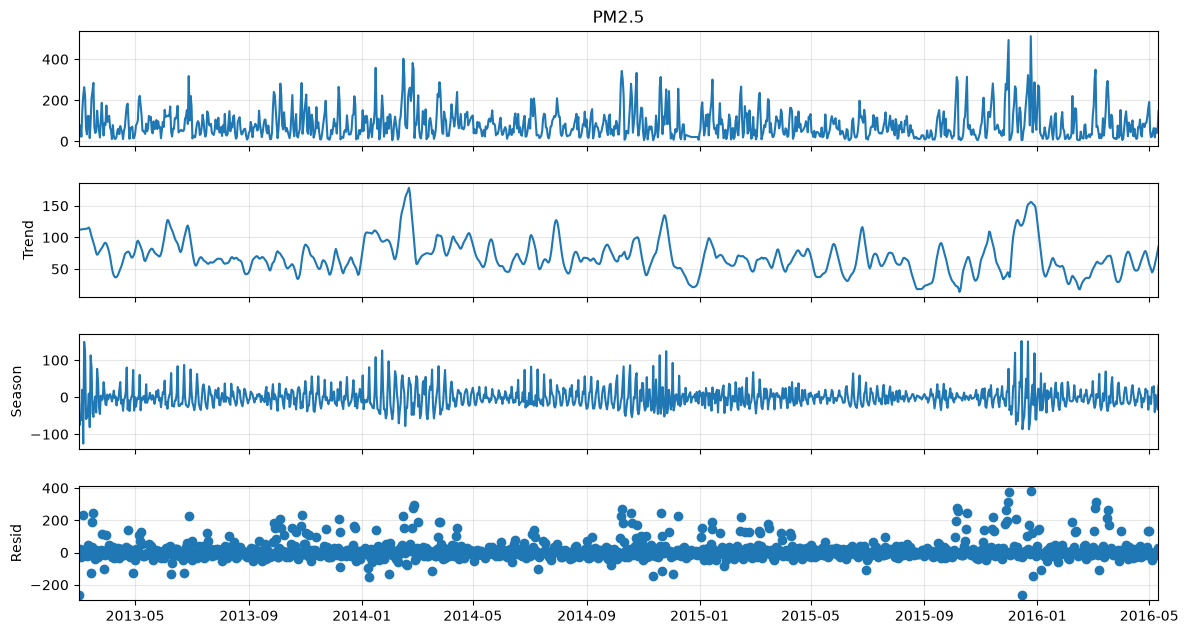

F_T=0.200  F_S=0.071


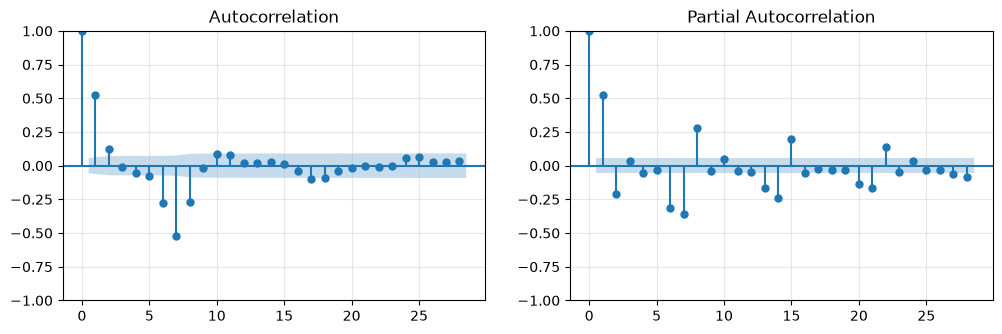

,PM2.5,TEMP,DEWP,PRES,WSPM
PM2.5,1.000,-0.087,0.142,-0.017,-0.380
TEMP,-0.087,1.000,0.899,-0.862,-0.197
DEWP,0.142,0.899,1.000,-0.789,-0.450
PRES,-0.017,-0.862,-0.789,1.000,0.176
WSPM,-0.380,-0.197,-0.450,0.176,1.000


In [6]:
y_dev = desarrollo[OBJ]
for nombre, z in [("nivel", y_dev), (f"(1-B^{PER})", y_dev.diff(PER).dropna()),
                  (f"(1-B)(1-B^{PER})", y_dev.diff().diff(PER).dropna())]:
    print(f"{nombre:<20s} ADF p={adfuller(z, autolag='AIC')[1]:.4f} | KPSS p={kpss(z, nlags='auto')[1]:.4f}")

stl = STL(y_dev, period=PER, robust=True).fit()
stl.plot(); plt.gcf().set_size_inches(12, 7); plt.show()
F_T = max(0, 1 - np.var(stl.resid)/np.var(stl.trend + stl.resid))
F_S = max(0, 1 - np.var(stl.resid)/np.var(stl.seasonal + stl.resid))
print(f"F_T={F_T:.3f}  F_S={F_S:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(y_dev.diff(PER).dropna(), lags=4*PER, ax=ax[0]); plot_pacf(y_dev.diff(PER).dropna(), lags=4*PER, ax=ax[1], method="ywm")
plt.show()
if EXO:
    display(desarrollo.corr().round(3))

## 6. Validación cruzada de origen móvil
Para el pliegue $k$ con origen $o_k$: se entrena con $\{1,\dots,o_k-1\}$ (o una ventana deslizante) y se evalúa en $\{o_k,\dots,o_k+H-1\}$. Los orígenes se reparten en el último 40% del bloque de desarrollo. Así se respeta el orden temporal (Bergmeir & Benítez, 2012; Hyndman & Athanasopoulos, 2021, §5.10).

In [7]:
def pliegues_origen_movil(n, n_pliegues, H, ventana="expandible", long_vent=2000, inicio=0.6):
    o_min, o_max = int(inicio*n), n - H
    origenes = np.linspace(o_min, o_max, n_pliegues).astype(int)
    for o in origenes:
        ini = 0 if ventana == "expandible" else max(0, o - long_vent)
        yield np.arange(ini, o), np.arange(o, o + H)

for k, (itr, ite) in enumerate(pliegues_origen_movil(len(desarrollo), N_PLIEGUES, HORIZONTE, VENTANA, LONG_VENTANA_DESLIZANTE)):
    print(f"Pliegue {k+1}: entrena {desarrollo.index[itr[0]]} a {desarrollo.index[itr[-1]]} "
          f"-> evalúa {desarrollo.index[ite[0]]} a {desarrollo.index[ite[-1]]}")

Pliegue 1: entrena 2013-03-01 00:00:00 a 2015-01-29 00:00:00 -> evalúa 2015-01-30 00:00:00 a 2015-02-22 00:00:00
Pliegue 2: entrena 2013-03-01 00:00:00 a 2015-05-20 00:00:00 -> evalúa 2015-05-21 00:00:00 a 2015-06-13 00:00:00
Pliegue 3: entrena 2013-03-01 00:00:00 a 2015-09-08 00:00:00 -> evalúa 2015-09-09 00:00:00 a 2015-10-02 00:00:00
Pliegue 4: entrena 2013-03-01 00:00:00 a 2015-12-28 00:00:00 -> evalúa 2015-12-29 00:00:00 a 2016-01-21 00:00:00
Pliegue 5: entrena 2013-03-01 00:00:00 a 2016-04-17 00:00:00 -> evalúa 2016-04-18 00:00:00 a 2016-05-11 00:00:00


## 7. Modelos
**Contrato de todos los modelos:** `pronosticar(y_hist, X_hist, X_fut, H, **hp) -> np.ndarray de largo H`.
- `y_hist`: Serie (pandas) de entrenamiento del pliegue. `X_hist`: DataFrame de exógenas alineado (puede estar vacío).
- `X_fut`: exógenas del horizonte (supuesto de exógena conocida; si el equipo pronostica la exógena, debe hacerlo dentro de esta función).
- `hp`: hiperparámetros, para el análisis de sensibilidad.
- Dentro de la función se ajusta TODO lo dependiente de datos (escaladores, tendencias): así no hay fuga.

In [8]:
import tensorflow as tf
from statsmodels.tsa.statespace.sarimax import SARIMAX

def ingenuo_estacional(y_hist, X_hist, X_fut, H, **hp):
    # Referencia obligatoria: repite el último ciclo estacional observado.
    ult = y_hist.values[-PER:]
    return np.array([ult[h % PER] for h in range(H)])

def modelo_clasico(y_hist, X_hist, X_fut, H, order=(1, 0, 1), seasonal_order=(0, 0, 0, 0), **hp):
    # SARIMAX sobre log(1 + PM2.5) con las variables meteorológicas como exógenas.
    # Orden elegido con el AIC en desarrollo; la estacionalidad semanal es débil (F_S de la sección 5).
    z = np.log1p(y_hist.values)
    m = SARIMAX(z, exog=X_hist.values, order=order, seasonal_order=seasonal_order, trend="c").fit(disp=False)
    f = m.get_forecast(H, exog=X_fut.values)
    # exp(media + varianza/2) devuelve la media en la escala original y no la mediana.
    return np.expm1(f.predicted_mean + f.var_pred_mean / 2)

def modelo_neuronal(y_hist, X_hist, X_fut, H, dy=3, dx=1, neuronas=16, l2=1e-4, epocas=400, paciencia=30,
                    semilla=SEMILLA, **hp):
    # NARX: [z_{t-1..t-dy}, x_{t..t-dx}] -> z_t, con z = log(1 + PM2.5).
    z = np.log1p(y_hist.values)
    X = np.vstack([X_hist.values, X_fut.values])
    n = len(z)
    mu_z, sd_z = z.mean(), z.std()                       # escalado solo con el entrenamiento del pliegue
    mu_x, sd_x = X[:n].mean(0), X[:n].std(0)
    zs = np.r_[(z - mu_z) / sd_z, np.zeros(H)]
    xs = (X - mu_x) / sd_x
    fila = lambda t: np.r_[zs[t-dy:t][::-1], xs[t-dx:t+1][::-1].ravel()]
    L0 = max(dy, dx)
    Z = np.array([fila(t) for t in range(L0, n)]); obj = zs[L0:n]
    n_va = int(0.15 * len(Z))                            # cola del entrenamiento para la parada temprana

    tf.keras.utils.set_random_seed(semilla); tf.keras.backend.clear_session()
    red = tf.keras.Sequential([tf.keras.Input(shape=(Z.shape[1],)),
                               tf.keras.layers.Dense(neuronas, activation="tanh",
                                                     kernel_regularizer=tf.keras.regularizers.l2(l2)),
                               tf.keras.layers.Dense(1)])
    red.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    red.fit(Z[:-n_va], obj[:-n_va], validation_data=(Z[-n_va:], obj[-n_va:]), epochs=epocas, batch_size=32,
            verbose=0, callbacks=[tf.keras.callbacks.EarlyStopping(patience=paciencia, restore_best_weights=True)])
    var_va = np.var(obj[-n_va:] - red(Z[-n_va:], training=False).numpy().ravel()) * sd_z**2

    for k in range(H):                                   # lazo cerrado: cada predicción entra como retardo
        zs[n + k] = red(fila(n + k)[None, :], training=False).numpy()[0, 0]
    return np.expm1(zs[n:] * sd_z + mu_z + var_va / 2)

MODELOS = {"Ingenuo estacional": (ingenuo_estacional, {}),
           "Clásico":            (modelo_clasico, {"order": (1, 0, 1), "seasonal_order": (0, 0, 0, 0)}),
           "Neuronal":           (modelo_neuronal, {"dy": 3, "neuronas": 16})}

## 8. Motor de evaluación (no modificar)

In [9]:
ESC_MASE = np.mean(np.abs(y_dev.values[PER:] - y_dev.values[:-PER]))   # escala MASE con desarrollo

def metricas(yr, yp):
    yr, yp = np.asarray(yr, float), np.asarray(yp, float); e = yr - yp
    nz = np.abs(yr) > 1e-8
    return {"RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e)),
            "MAPE(%)": 100*np.mean(np.abs(e[nz]/yr[nz])) if nz.any() else np.nan,
            "sMAPE(%)": 200*np.mean(np.abs(e)/(np.abs(yr)+np.abs(yp)+1e-12)), "MASE": np.mean(np.abs(e))/ESC_MASE}

def evaluar(fun, hp, base, pliegues):
    reales, preds, tiempo = [], [], 0.0
    for itr, ite in pliegues:
        yh, Xh = base[OBJ].iloc[itr], base[EXO].iloc[itr]
        Xf = base[EXO].iloc[ite]
        t0 = time.time()
        p = np.asarray(fun(yh, Xh, Xf, len(ite), **hp), float).ravel()
        tiempo += time.time() - t0
        assert p.shape == (len(ite),), "El modelo debe devolver H valores"
        reales.append(base[OBJ].iloc[ite].values); preds.append(p)
    return np.array(reales), np.array(preds), tiempo

def correr_benchmark(base, pliegues, modelos):
    res, salidas = {}, {}
    for nombre, (fun, hp) in modelos.items():
        try:
            R, P, tt = evaluar(fun, hp, base, list(pliegues))
        except NotImplementedError:
            print(f"[aviso] '{nombre}' aún no implementado: se omite."); continue
        res[nombre] = {**metricas(R.ravel(), P.ravel()), "Tiempo(s)": tt}
        salidas[nombre] = (R, P)
    return pd.DataFrame(res).T, salidas

pl_cv = list(pliegues_origen_movil(len(desarrollo), N_PLIEGUES, HORIZONTE, VENTANA, LONG_VENTANA_DESLIZANTE))
tabla_cv, salidas_cv = correr_benchmark(desarrollo, pl_cv, MODELOS)
print(f"Validación cruzada de origen móvil ({N_PLIEGUES} pliegues, H={HORIZONTE})"); display(tabla_cv.round(4))

Validación cruzada de origen móvil (5 pliegues, H=24)


,RMSE,MAE,MAPE(%),sMAPE(%),MASE,Tiempo(s)
Ingenuo estacional,110.5323,71.6894,194.2491,85.0649,1.0046,0.0001
Clásico,51.4663,37.0626,109.2049,56.0728,0.5193,2.5342
Neuronal,37.6095,28.7741,75.8528,47.2646,0.4032,101.1126


## 9. Análisis de sensibilidad de hiperparámetros
Defina una rejilla por modelo (mínimo 2 hiperparámetros × 3 niveles para el modelo neuronal). Se reporta media y desviación del RMSE por pliegue, y se recomienda repetir con ≥ 3 semillas para redes.

,order,seasonal_order,RMSE medio,RMSE desv,Tiempo(s)
3,"(1, 0, 1)","(0, 0, 0, 0)",49.9547,12.3821,13.0794
5,"(1, 0, 1)","(1, 0, 1, 7)",50.0894,10.7621,43.9936
4,"(1, 0, 1)","(1, 0, 0, 7)",51.5381,10.8054,44.7597
8,"(2, 0, 1)","(1, 0, 1, 7)",51.8879,9.8846,10.8941
1,"(1, 0, 0)","(1, 0, 0, 7)",52.0010,10.5491,26.0057
0,"(1, 0, 0)","(0, 0, 0, 0)",52.8108,11.3970,8.4576
2,"(1, 0, 0)","(1, 0, 1, 7)",52.8232,9.7703,42.8634
6,"(2, 0, 1)","(0, 0, 0, 0)",53.0976,11.9857,13.6865
7,"(2, 0, 1)","(1, 0, 0, 7)",128.9696,152.7340,12.3094


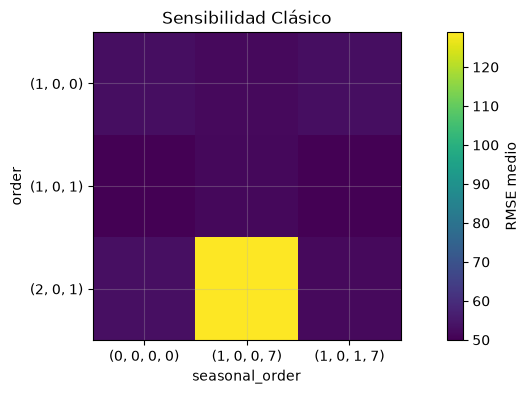

,dy,neuronas,semilla,RMSE medio,RMSE desv,Tiempo(s)
3,1,8,1,34.2614,9.2435,119.2324
15,3,16,1,35.0668,12.2853,99.6725
7,1,16,2,35.5868,8.9713,94.5812
16,3,16,2,36.0537,12.9003,76.6534
8,1,16,3,36.1062,8.0164,84.6867
5,1,8,3,36.1900,8.6927,69.2365
4,1,8,2,36.1919,11.3033,316.2353
6,1,16,1,36.9763,11.5743,109.7440
0,1,4,1,37.6669,7.3025,139.0953
1,1,4,2,37.7463,10.2287,100.2457


In [10]:
REJILLAS = {
    "Clásico":  {"order": [(1, 0, 0), (1, 0, 1), (2, 0, 1)],
                 "seasonal_order": [(0, 0, 0, 0), (1, 0, 0, PER), (1, 0, 1, PER)]},
    "Neuronal": {"dy": [1, 3, 7], "neuronas": [4, 8, 16], "semilla": [1, 2, 3]},
}

def sensibilidad(nombre, rejilla):
    fun, hp_base = MODELOS[nombre]
    claves = list(rejilla)
    filas = []
    for valores in itertools.product(*[rejilla[k] for k in claves]):
        hp = {**hp_base, **dict(zip(claves, valores))}
        R, P, tt = evaluar(fun, hp, desarrollo, pl_cv)
        rmse_pl = np.sqrt(np.mean((R - P)**2, axis=1))
        filas.append({**dict(zip(claves, valores)), "RMSE medio": rmse_pl.mean(), "RMSE desv": rmse_pl.std(), "Tiempo(s)": tt})
    t = pd.DataFrame(filas).sort_values("RMSE medio"); display(t.round(4))
    if len(claves) == 2:   # mapa de calor para dos hiperparámetros
        piv = t.pivot(index=claves[0], columns=claves[1], values="RMSE medio")
        plt.imshow(piv, cmap="viridis"); plt.colorbar(label="RMSE medio")
        plt.xticks(range(piv.shape[1]), piv.columns); plt.yticks(range(piv.shape[0]), piv.index)
        plt.xlabel(claves[1]); plt.ylabel(claves[0]); plt.title(f"Sensibilidad {nombre}"); plt.show()
    return t

tablas_sens = {m: sensibilidad(m, g) for m, g in REJILLAS.items()}

RMSE medio (semillas)  desv entre semillas
dy neuronas                                            
1  8                        35.548                1.114
   16                       36.223                0.702
3  16                       36.505                1.709
1  4                        37.757                0.095
3  8                        39.077                0.566
   4                        40.393                1.020
7  4                        40.581                2.782
   8                        42.898                1.935
   16                       43.232                1.002

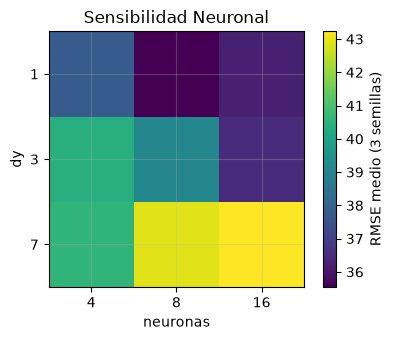

Elegidos: {'Ingenuo estacional': {}, 'Clásico': {'order': (1, 0, 1), 'seasonal_order': (0, 0, 0, 0)}, 'Neuronal': {'dy': 1, 'neuronas': 8}}


Validación cruzada con los hiperparámetros elegidos


,RMSE,MAE,MAPE(%),sMAPE(%),MASE,Tiempo(s)
Ingenuo estacional,110.5323,71.6894,194.2491,85.0649,1.0046,0.0002
Clásico,51.4663,37.0626,109.2049,56.0728,0.5193,2.7077
Neuronal,40.0733,28.8076,79.9645,45.5880,0.4037,141.6404


In [11]:
# Selección por validación cruzada: la combinación de menor RMSE medio. En la red se promedian las tres semillas.
os.makedirs("resultados", exist_ok=True)
t_cl = tablas_sens["Clásico"]
mejor_cl = t_cl.iloc[0]
neu = (tablas_sens["Neuronal"].groupby(["dy", "neuronas"])["RMSE medio"].agg(["mean", "std"])
       .rename(columns={"mean": "RMSE medio (semillas)", "std": "desv entre semillas"}).sort_values("RMSE medio (semillas)"))
display(neu.round(3)); neu.to_csv("resultados/sensibilidad_Neuronal_por_semillas.csv")
dy_sel, n_sel = neu.index[0]

piv = neu["RMSE medio (semillas)"].unstack()
plt.figure(figsize=(4.5, 3.5)); plt.imshow(piv, cmap="viridis"); plt.colorbar(label="RMSE medio (3 semillas)")
plt.xticks(range(piv.shape[1]), piv.columns); plt.yticks(range(piv.shape[0]), piv.index)
plt.xlabel("neuronas"); plt.ylabel("dy"); plt.title("Sensibilidad Neuronal"); plt.tight_layout(); plt.show()

MODELOS["Clásico"]  = (modelo_clasico, {"order": mejor_cl["order"], "seasonal_order": mejor_cl["seasonal_order"]})
MODELOS["Neuronal"] = (modelo_neuronal, {"dy": int(dy_sel), "neuronas": int(n_sel)})
print("Elegidos:", {m: hp for m, (_, hp) in MODELOS.items()})
tabla_cv, salidas_cv = correr_benchmark(desarrollo, pl_cv, MODELOS)
print("Validación cruzada con los hiperparámetros elegidos"); display(tabla_cv.round(4))

## 10. Evaluación final en la prueba externa (una sola vez, con los hiperparámetros elegidos)

Prueba externa: 12 orígenes, H=24


,RMSE,MAE,MAPE(%),sMAPE(%),MASE,Tiempo(s)
Ingenuo estacional,96.2395,69.4932,175.6126,86.3006,0.9738,0.0003
Clásico,70.1776,49.6345,110.5766,61.1110,0.6955,11.6674
Neuronal,44.0225,28.7534,53.4979,41.0836,0.4029,400.3275


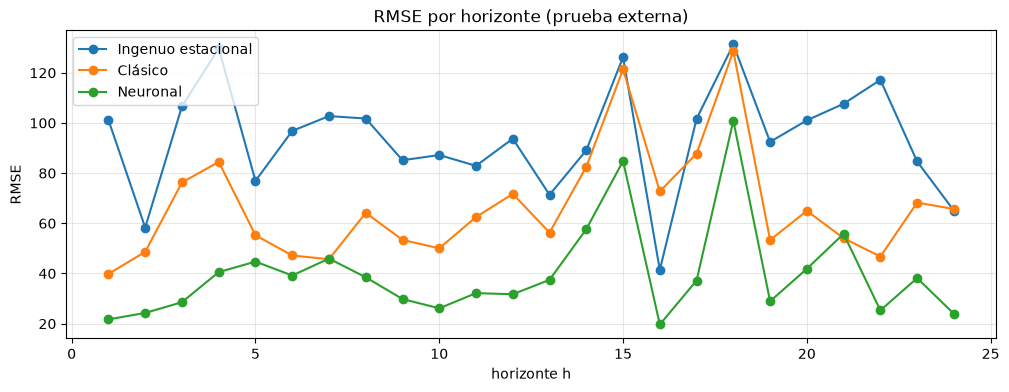

In [12]:
pl_test = list(pliegues_origen_movil(N, max(1, (len(prueba) - HORIZONTE)//HORIZONTE + 1), HORIZONTE,
                                     VENTANA, LONG_VENTANA_DESLIZANTE, inicio=n_dev/N))
tabla_test, salidas_test = correr_benchmark(datos, pl_test, MODELOS)
print(f"Prueba externa: {len(pl_test)} orígenes, H={HORIZONTE}"); display(tabla_test.round(4))

plt.figure()
for m, (R, P) in salidas_test.items():
    plt.plot(range(1, HORIZONTE+1), np.sqrt(np.mean((R-P)**2, axis=0)), marker="o", label=m)
plt.xlabel("horizonte h"); plt.ylabel("RMSE"); plt.title("RMSE por horizonte (prueba externa)"); plt.legend(); plt.show()

## 11. Residuos y significancia estadística

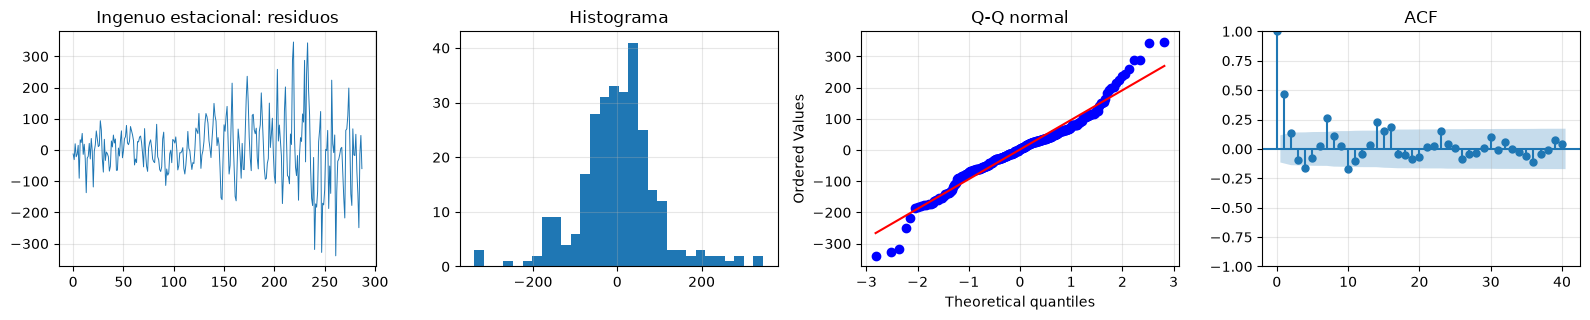

   lb_stat  lb_pvalue
7  102.272        0.0


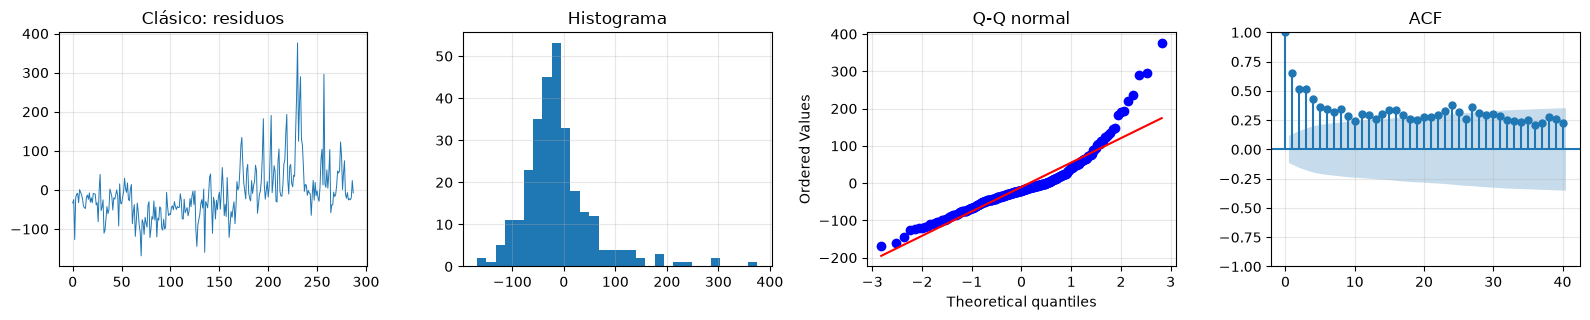

    lb_stat  lb_pvalue
7  437.2843        0.0


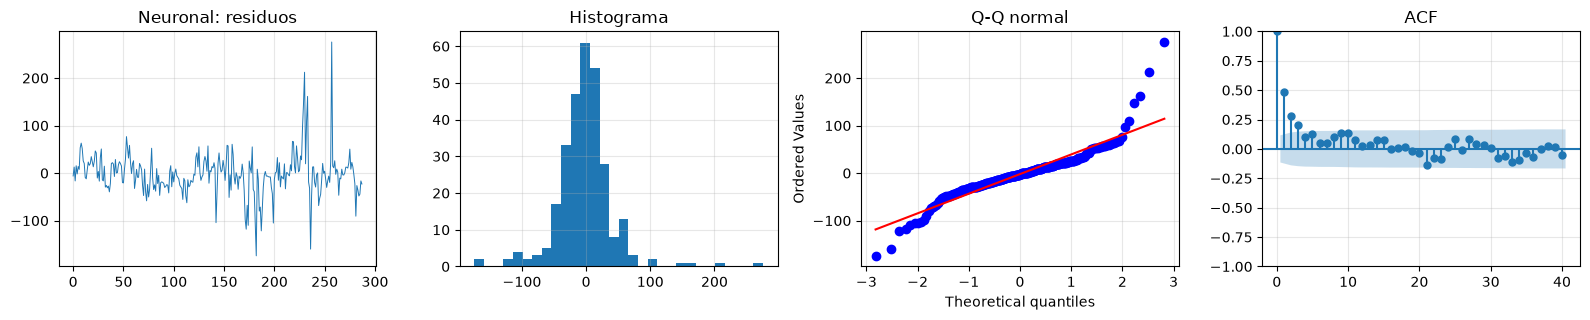

    lb_stat  lb_pvalue
7  110.8486        0.0
DM Ingenuo estacional vs Clásico: DM*=1.742, p=0.0826
DM Ingenuo estacional vs Neuronal: DM*=2.427, p=0.0159
DM Clásico vs Neuronal: DM*=2.983, p=0.0031


In [13]:
def graficar_residuos(nombre, R, P):
    e_all = (R - P).ravel()
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.3))
    ax[0].plot(e_all, lw=.7); ax[0].set_title(f"{nombre}: residuos")
    ax[1].hist(e_all, bins=30); ax[1].set_title("Histograma")
    stats.probplot(e_all, dist="norm", plot=ax[2]); ax[2].set_title("Q-Q normal")
    plot_acf(e_all, lags=min(40, len(e_all)//3), ax=ax[3]); ax[3].set_title("ACF")
    plt.tight_layout(); plt.show()
    print(acorr_ljungbox(e_all, lags=[min(PER, len(e_all)//4)]).round(4))

def diebold_mariano(e1, e2, h=1):
    d = e1**2 - e2**2; T = len(d)
    g = [np.sum((d[k:]-d.mean())*(d[:T-k]-d.mean()))/T for k in range(h)]
    dm = d.mean()/np.sqrt((g[0] + 2*sum(g[1:]))/T) * np.sqrt((T+1-2*h+h*(h-1)/T)/T)
    return dm, 2*stats.t.sf(abs(dm), T-1)

for m, (R, P) in salidas_test.items():
    graficar_residuos(m, R, P)
nombres = list(salidas_test)
for a, b in itertools.combinations(nombres, 2):
    Ra, Pa = salidas_test[a]; Rb, Pb = salidas_test[b]
    dm, p = diebold_mariano((Ra-Pa).ravel(), (Rb-Pb).ravel(), h=HORIZONTE)
    print(f"DM {a} vs {b}: DM*={dm:.3f}, p={p:.4f}")

## 12. Exportación para el informe

In [14]:
os.makedirs("resultados", exist_ok=True)
tabla_cv.to_csv("resultados/benchmark_cv.csv"); tabla_test.to_csv("resultados/benchmark_prueba.csv")
for m, t in tablas_sens.items():
    t.to_csv(f"resultados/sensibilidad_{m}.csv", index=False)
json.dump({"dataset": DATASET, "objetivo": OBJ, "exogenas": EXO, "frecuencia": FREC, "S": PER,
           "horizonte": HORIZONTE, "pliegues": N_PLIEGUES, "ventana": VENTANA,
           "hiperparametros": {m: hp for m, (_, hp) in MODELOS.items()}},
          open("resultados/configuracion.json", "w"), indent=2, default=str)
print("Archivos en ./resultados:", os.listdir("resultados"))

Archivos en ./resultados: ['benchmark_cv.csv', 'benchmark_prueba.csv', 'configuracion.json', 'sensibilidad_Clásico.csv', 'sensibilidad_Neuronal.csv', 'sensibilidad_Neuronal_por_semillas.csv']
